In [2]:
import os 
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp

In [3]:
# Paths
rosmap_path = "/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/scanpy/Astrocytes.h5ad"
seaad_path  = "/Users/ga0028vi/Documents/MCcharactertization/SEAAD_PFC/_core_data/SEAAD_PFC_finalnuclei_Astrocytes.h5ad"
out_dir     = "/Users/ga0028vi/Documents/MCcharactertization/label_transfer/notebook/"
os.makedirs(out_dir, exist_ok=True)

# Load
rosmap = sc.read_h5ad(rosmap_path)
seaad  = sc.read_h5ad(seaad_path)

In [4]:
###### CLEAN ROSMAP
rosmap.obs["projid"] = rosmap.obs["projid"].astype(str)
rosmap.obs["newdons"] = rosmap.obs["projid"]
rosmap.obs["cellsubtypes"] = rosmap.obs["cell_type_high_resolution"].astype(str).str.replace("_", "", regex=True)
rosmap.X = rosmap.layers["counts"]  # use raw counts, but irrelevant for exc


In [5]:
# SEAAD cleanup
seaad.obs["Donor ID"] = seaad.obs["Donor ID"].astype(str).str.replace(".", "", regex=False)
seaad.obs["newdons"] = seaad.obs["Donor ID"]
seaad.obs["cellsubtypes"] = seaad.obs["Supertype"].astype(str)

cols_to_drop = [
    "Race (choice=White)", "Race (choice=Black/ African American)", "Race (choice=Asian)",
    "Race (choice=American Indian/ Alaska Native)", "Race (choice=Native Hawaiian or Pacific Islander)",
    "Race (choice=Unknown or unreported)", "Race (choice=Other)", "specify other race",
    "Hispanic/Latino", "Highest level of education", "Years of education", "PMI",
    "Fresh Brain Weight", "Brain pH", "Overall AD neuropathological Change", "Thal", "Braak",
    "CERAD score", "Overall CAA Score", "Highest Lewy Body Disease",
    "Total Microinfarcts (not observed grossly)", "Total microinfarcts in screening sections",
    "Atherosclerosis", "Arteriolosclerosis", "LATE", "Cognitive Status",
    "Last CASI Score", "Interval from last CASI in months", "Last MMSE Score",
    "Interval from last MMSE in months", "Last MOCA Score", "Interval from last MOCA in months",
    "APOE Genotype", "Primary Study Name", "Secondary Study Name", "NeuN positive fraction on FANS",
    "RIN", "cell_prep_type", "facs_population_plan", "rna_amplification", "sample_name",
    "sample_quantity_count", "expc_cell_capture", "method", "pcr_cycles",
    "percent_cdna_longer_than_400bp", "rna_amplification_pass_fail", "amplified_quantity_ng",
    "load_name", "library_prep", "library_input_ng", "r1_index", "avg_size_bp",
    "quantification_fmol", "library_prep_pass_fail", "exp_component_vendor_name",
    "batch_vendor_name", "experiment_component_failed", "alignment", "Genome", "ar_id", "bc",
    "GEX_Estimated_number_of_cells", "GEX_number_of_reads", "GEX_sequencing_saturation",
    "GEX_Mean_raw_reads_per_cell", "GEX_Q30_bases_in_barcode", "GEX_Q30_bases_in_read_2",
    "GEX_Q30_bases_in_UMI", "GEX_Percent_duplicates", "GEX_Q30_bases_in_sample_index_i1",
    "GEX_Q30_bases_in_sample_index_i2", "GEX_Reads_with_TSO", "GEX_Sequenced_read_pairs",
    "GEX_Valid_UMIs", "GEX_Valid_barcodes", "GEX_Reads_mapped_to_genome",
    "GEX_Reads_mapped_confidently_to_genome", "GEX_Reads_mapped_confidently_to_intergenic_regions",
    "GEX_Reads_mapped_confidently_to_intronic_regions", "GEX_Reads_mapped_confidently_to_exonic_regions",
    "GEX_Reads_mapped_confidently_to_transcriptome", "GEX_Reads_mapped_antisense_to_gene",
    "GEX_Fraction_of_transcriptomic_reads_in_cells", "GEX_Total_genes_detected",
    "GEX_Median_UMI_counts_per_cell", "GEX_Median_genes_per_cell",
    "Multiome_Feature_linkages_detected", "Multiome_Linked_genes", "Multiome_Linked_peaks",
    "ATAC_Confidently_mapped_read_pairs", "ATAC_Fraction_of_genome_in_peaks",
    "ATAC_Fraction_of_high_quality_fragments_in_cells", "ATAC_Fraction_of_high_quality_fragments_overlapping_TSS",
    "ATAC_Fraction_of_high_quality_fragments_overlapping_peaks", "ATAC_Fraction_of_transposition_events_in_peaks_in_cells",
    "ATAC_Mean_raw_read_pairs_per_cell", "ATAC_Median_high_quality_fragments_per_cell",
    "ATAC_Non-nuclear_read_pairs", "ATAC_Number_of_peaks", "ATAC_Percent_duplicates",
    "ATAC_Q30_bases_in_barcode", "ATAC_Q30_bases_in_read_1", "ATAC_Q30_bases_in_read_2",
    "ATAC_Q30_bases_in_sample_index_i1", "ATAC_Sequenced_read_pairs", "ATAC_TSS_enrichment_score",
    "ATAC_Unmapped_read_pairs", "ATAC_Valid_barcodes", "Number of mapped reads",
    "Number of unmapped reads", "Number of multimapped reads", "Number of reads",
    "Number of UMIs", "Genes detected", "Doublet score", "Fraction mitochondrial UMIs",
    "Used in analysis", "Class confidence", "Class", "Subclass confidence", "Supertype confidence",
    "Supertype (non-expanded)", "Continuous Pseudo-progression Score", "Organism",
    "Neurotypical reference", "Brain Region", "Sex", "Gender", "Age at Death",
    "Severely Affected Donor"
]
seaad.obs = seaad.obs.drop(columns=cols_to_drop, errors="ignore")
for attr in ["uns", "obsm", "obsp"]:
    if hasattr(seaad, attr):
        delattr(seaad, attr)

seaad.X = seaad.layers["UMIs"]  # use raw UMIs


In [8]:
# Filter
sc.pp.filter_cells(rosmap, min_genes=100)
sc.pp.filter_genes(rosmap, min_cells=3)
sc.pp.filter_cells(seaad,  min_genes=100)
sc.pp.filter_genes(seaad,  min_cells=3)

# Keep only common genes
common_genes = rosmap.var_names.intersection(seaad.var_names)
rosmap = rosmap[:, common_genes].copy()
seaad  = seaad[:, common_genes].copy()

# Normalize + log1p
sc.pp.normalize_total(rosmap)
sc.pp.log1p(rosmap)
sc.pp.normalize_total(seaad)
sc.pp.log1p(seaad)

# Clean subtype strings a bit
rosmap.obs["cellsubtypes"] = rosmap.obs["cellsubtypes"].str.replace(" ", "", regex=True)
seaad.obs["cellsubtypes"]  = seaad.obs["cellsubtypes"].str.replace(" ", "", regex=True)


In [9]:
seaad.obs

,sample_id,Donor ID,Subclass,Supertype,newdons,cellsubtypes,n_genes
exp_component_name,,,,,,,
GGTGGCTGTCTATGAC-L8TX_210624_01_G03-1116045510,GGTGGCTGTCTATGAC-L8TX_210624_01_G03-1116045510,H2033026,Astrocyte,Astro_2,H2033026,Astro_2,4073
GTGTTCCAGGACAGCT-L8TX_220106_03_E10-1151911969,GTGTTCCAGGACAGCT-L8TX_220106_03_E10-1151911969,H2033045,Astrocyte,Astro_3,H2033045,Astro_3,2702
CCTCAGTTCGTAGGGA-L8TX_211007_01_A10-1135089113,CCTCAGTTCGTAGGGA-L8TX_211007_01_A10-1135089113,H2133028,Astrocyte,Astro_2,H2133028,Astro_2,5520
TACCGTTGTTAGGACC-L8XR_220210_03_G06-1161252190,TACCGTTGTTAGGACC-L8XR_220210_03_G06-1161252190,H2133001,Astrocyte,Astro_6-SEAAD,H2133001,Astro_6-SEAAD,3063
AAACGAAGTTAACCTG-L8TX_210805_01_C03-1122820129,AAACGAAGTTAACCTG-L8TX_210805_01_C03-1122820129,H2033033,Astrocyte,Astro_3,H2033033,Astro_3,4739
...,...,...,...,...,...,...,...
TTCCGTGGTCGCGTTG-L8TX_210805_01_A03-1122806996,TTCCGTGGTCGCGTTG-L8TX_210805_01_A03-1122806996,H2033016,Astrocyte,Astro_2,H2033016,Astro_2,3135
TGTCCACAGACCTGGA-L8TX_220120_02_B03-1155539599,TGTCCACAGACCTGGA-L8TX_220120_02_B03-1155539599,H2133002,Astrocyte,Astro_2,H2133002,Astro_2,6121
ACAGAAACAGACACAG-L8TX_210909_01_A03-1129997617,ACAGAAACAGACACAG-L8TX_210909_01_A03-1129997617,H2133032,Astrocyte,Astro_2,H2133032,Astro_2,3479


In [10]:
rosmap.obs

,projid,cell_type_high_resolution,newdons,cellsubtypes,n_genes
CACATTTCAAGTCTAC-1-0,11409232,Ast GRM3,11409232,AstGRM3,2675
GAAGCAGCAGCTCCGA-1-0,11409232,Ast CHI3L1,11409232,AstCHI3L1,2903
GCGCGATCAGCCTGTG-1-0,11409232,Ast CHI3L1,11409232,AstCHI3L1,2655
TCACGAAGTGCAGGTA-1-0,11409232,Ast GRM3,11409232,AstGRM3,2923
TTTCCTCCAATGACCT-1-0,11409232,Ast CHI3L1,11409232,AstCHI3L1,3036
...,...,...,...,...,...
TTGAACGCATCGATCA-16-14,41285665,Ast GRM3,41285665,AstGRM3,3839
TTGAGTGCATTATGCG-16-14,41285665,Ast DPP10,41285665,AstDPP10,3835
TTGATGGCAATAGGAT-16-14,41285665,Ast CHI3L1,41285665,AstCHI3L1,3563
TTGGTTTGTGCTTCAA-16-14,41285665,Ast DPP10,41285665,AstDPP10,605


In [11]:
# Pseudobulk by subtype
def pseudobulk_by_subtype(adata):
    if not sp.sparse.issparse(adata.X):
        adata.X = sp.sparse.csr_matrix(adata.X)

    sub = adata.obs["cellsubtypes"].astype("category")
    codes = sub.cat.codes.values
    levels = list(sub.cat.categories)

    n_cells = adata.n_obs
    n_groups = len(levels)

    # indicator matrix: group x cell
    mtx = sp.sparse.csr_matrix(
        (np.ones(n_cells, dtype=np.float32), (codes, np.arange(n_cells))),
        shape=(n_groups, n_cells)
    )

    sums = mtx @ adata.X
    sizes = np.asarray(mtx.sum(axis=1)).ravel()
    means = sums.multiply(1.0 / sizes[:, None])

    return pd.DataFrame(means.toarray(), index=levels, columns=adata.var_names)


In [26]:
ros_pb_all = pseudobulk_by_subtype(rosmap)
sea_pb_all = pseudobulk_by_subtype(seaad)

In [29]:
# Correlation matrix (vectorized)
# corr(ros_subtype_i, sea_subtype_j) across genes
corr_all = np.corrcoef(ros_pb_all.values, sea_pb_all.values)
expr_sim_all = pd.DataFrame(
    corr_all[:ros_pb_all.shape[0], ros_pb_all.shape[0]:],
    index=ros_pb_all.index,
    columns=sea_pb_all.index
)

In [22]:
from sklearn.preprocessing import StandardScaler

# Z-score genes columnwise
ros_z_all = pd.DataFrame(StandardScaler().fit_transform(ros_pb_all),
                         index=ros_pb_all.index, columns=ros_pb_all.columns)
sea_z_all = pd.DataFrame(StandardScaler().fit_transform(sea_pb_all),
                         index=sea_pb_all.index, columns=sea_pb_all.columns)

# get corrs
corr_all = np.corrcoef(ros_z_all.values, sea_z_all.values)
expr_sim_all = pd.DataFrame(
    corr_all[:ros_z_all.shape[0], ros_z_all.shape[0]:],
    index=ros_z_all.index,
    columns=sea_z_all.index
)

In [25]:
expr_sim_all

,Astro_1,Astro_2,Astro_3,Astro_4,Astro_5,Astro_6-SEAAD
AstCHI3L1,0.154263,0.144706,-0.196172,-0.252126,-0.179716,0.336359
AstDPP10,-0.306746,-0.519071,0.402624,0.304529,0.124306,-0.078192
AstGRM3,0.194465,0.452512,-0.261941,-0.088036,0.045556,-0.265609


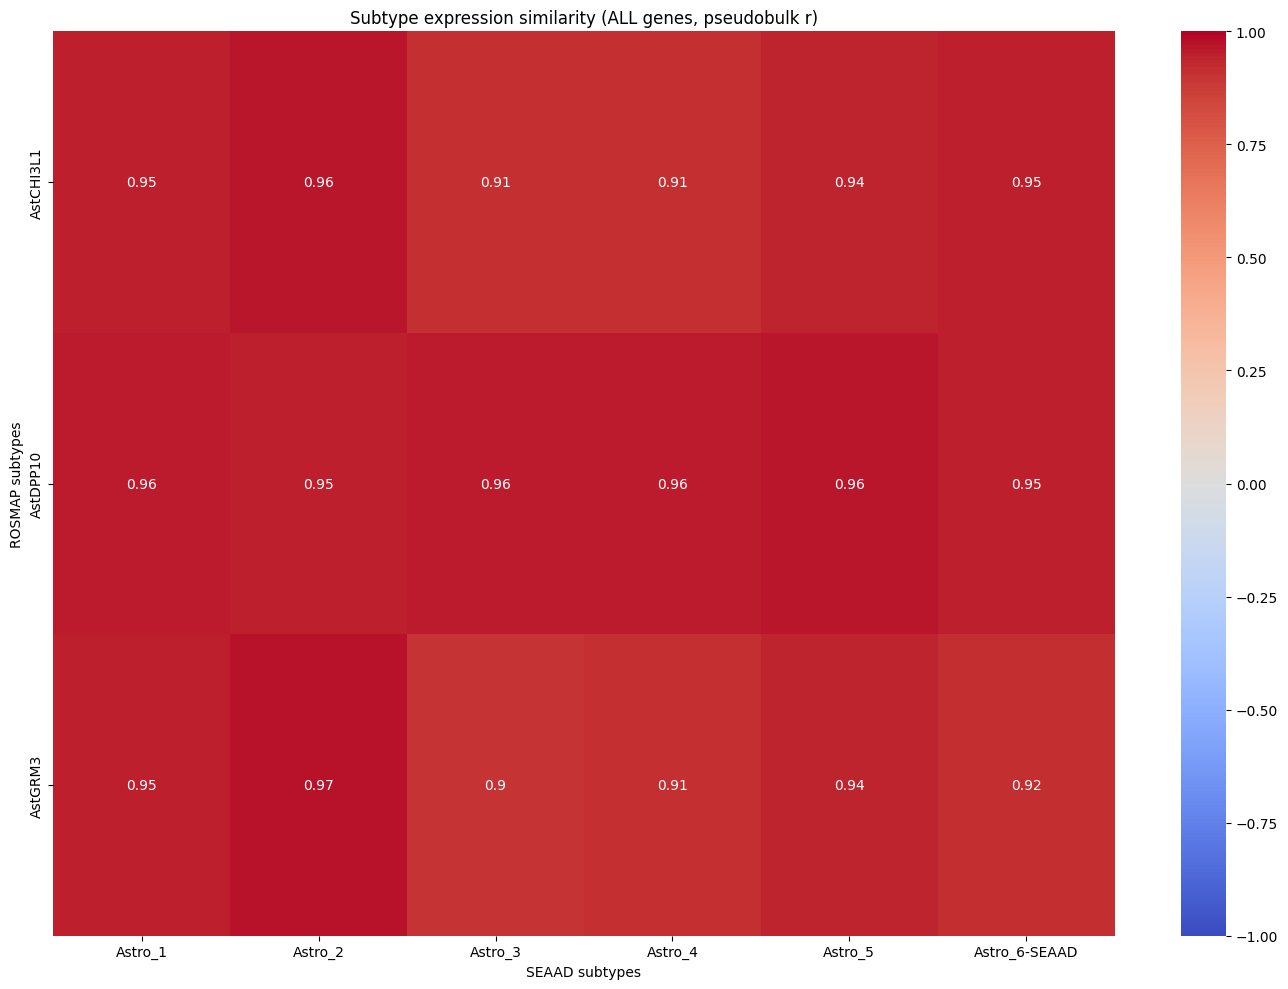

In [30]:
plt.figure(figsize=(14, 10))
sns.heatmap(expr_sim_all, vmin=-1, vmax=1, cmap="coolwarm", annot=True)
plt.xlabel("SEAAD subtypes")
plt.ylabel("ROSMAP subtypes")
plt.title("Subtype expression similarity (ALL genes, pseudobulk r)")
plt.tight_layout()